<a href="https://colab.research.google.com/github/arikelasumanjali-coder/DL/blob/main/VisionPort_skill_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Thu Nov 12 05:03:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import sys
import subprocess
import importlib.util

print("Python:", sys.version)

print("\n--- CUDA Toolkit ---")
subprocess.run(["nvcc", "--version"])

print("\n--- Installed Packages ---")
for package in ["torch", "ultralytics", "cv2", "tensorrt"]:
    print(package, ":", importlib.util.find_spec(package))

print("\n--- Triton Server ---")
subprocess.run(["which", "tritonserver"])

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

--- CUDA Toolkit ---

--- Installed Packages ---
torch : ModuleSpec(name='torch', loader=<_frozen_importlib_external.SourceFileLoader object at 0x78c359344b30>, origin='/usr/local/lib/python3.13/dist-packages/torch/__init__.py', submodule_search_locations=['/usr/local/lib/python3.13/dist-packages/torch'])
ultralytics : None
cv2 : ModuleSpec(name='cv2', loader=<google.colab._import_hooks._hook_injector.HookInjectorLoader object at 0x78c359433a10>)
tensorrt : None

--- Triton Server ---


CompletedProcess(args=['which', 'tritonserver'], returncode=1)

In [ ]:
%pip install -q ultralytics onnx tensorrt-cu13 "tritonclient[http]"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
import tensorrt as trt
import ultralytics
import onnx
import tritonclient.http as httpclient

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("TensorRT:", trt.__version__)
print("Ultralytics:", ultralytics.__version__)
print("ONNX:", onnx.__version__)
print("Triton Client: Installed")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
TensorRT: 11.4.0.106
Ultralytics: 8.4.211
ONNX: 1.23.2
Triton Client: Installed


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("Model loaded successfully!")
print("Model: YOLOv8 Nano")
print("Weights: yolov8n.pt")

Model loaded successfully!
Model: YOLOv8 Nano
Weights: yolov8n.pt


In [ ]:
# Export YOLOv8 to ONNX format
onnx_path = model.export(
    format="onnx",
    imgsz=640,
    batch=1,
    opset=17,
    simplify=False
)

print("ONNX export completed!")
print("ONNX file:", onnx_path)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from 'yolov8n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 0.9s, saved as 'yolov8n.onnx' (12.2 MB)

Export complete (1.3s)
Results saved to /content/yolov8n.onnx
Predict:         yolo predict task=detect model=yolov8n.onnx imgsz=640 
Validate:        yolo val task=detect model=yolov8n.onnx imgsz=640 data=coco.yaml 
Visualize:       https://netron.app
ONNX export completed!
ONNX file: yolov8n.onnx


In [ ]:
import tensorrt as trt
import torch
import os
import shutil

print("TensorRT version:", trt.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU compute capability:", torch.cuda.get_device_capability(0))
print("ONNX file exists:", os.path.exists("/content/yolov8n.onnx"))
print("ONNX file size:", round(os.path.getsize("/content/yolov8n.onnx") / (1024 * 1024), 2), "MB")
print("trtexec available:", shutil.which("trtexec"))

logger = trt.Logger(trt.Logger.INFO)
builder = trt.Builder(logger)

print("TensorRT builder initialized:", builder is not None)

TensorRT version: 11.4.0.106
GPU: Tesla T4
GPU compute capability: (7, 5)
ONNX file exists: True
ONNX file size: 12.23 MB
trtexec available: None
TensorRT builder initialized: True


In [ ]:
import tensorrt as trt
import os

logger = trt.Logger(trt.Logger.WARNING)
builder = trt.Builder(logger)

# TensorRT 11: explicit batch is the default
network = builder.create_network()

parser = trt.OnnxParser(network, logger)

# Load ONNX model
with open("/content/yolov8n.onnx", "rb") as f:
    onnx_data = f.read()

# Parse ONNX
if not parser.parse(onnx_data):
    for i in range(parser.num_errors):
        print(parser.get_error(i))
    raise RuntimeError("ONNX parsing failed")

print("ONNX parsing successful!")
print("Network layers:", network.num_layers)

# Configure TensorRT
config = builder.create_builder_config()

config.set_memory_pool_limit(
    trt.MemoryPoolType.WORKSPACE,
    2 * 1024**3
)

# TensorRT 11 uses strongly typed networks.
# Do not use the old BuilderFlag.FP16 flag.

print("Building TensorRT engine...")

serialized_engine = builder.build_serialized_network(
    network,
    config
)

if serialized_engine is None:
    raise RuntimeError("TensorRT engine build failed")

# Save engine
engine_path = "/content/yolov8n.engine"

with open(engine_path, "wb") as f:
    f.write(serialized_engine)

print("\nTensorRT engine created successfully!")
print("Engine path:", engine_path)
print(
    "Engine size:",
    round(os.path.getsize(engine_path) / (1024**2), 2),
    "MB"
)

ONNX parsing successful!
Network layers: 309
Building TensorRT engine...

TensorRT engine created successfully!
Engine path: /content/yolov8n.engine
Engine size: 163.86 MB


In [ ]:
import tensorrt as trt
import os

logger = trt.Logger(trt.Logger.WARNING)
runtime = trt.Runtime(logger)

with open("/content/yolov8n.engine", "rb") as f:
    engine_data = f.read()

engine = runtime.deserialize_cuda_engine(engine_data)

if engine is None:
    raise RuntimeError("Engine loading failed!")

print("TensorRT engine loaded successfully!")
print("Number of I/O tensors:", engine.num_io_tensors)

for i in range(engine.num_io_tensors):
    name = engine.get_tensor_name(i)
    print(
        name,
        "| Shape:", engine.get_tensor_shape(name),
        "| Data type:", engine.get_tensor_dtype(name),
        "| Mode:", engine.get_tensor_mode(name)
    )

TensorRT engine loaded successfully!
Number of I/O tensors: 2
images | Shape: (1, 3, 640, 640) | Data type: DataType.FLOAT | Mode: TensorIOMode.INPUT
output0 | Shape: (1, 84, 8400) | Data type: DataType.FLOAT | Mode: TensorIOMode.OUTPUT


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Uploaded image:", image_path)

Saving traffic_image.jpg to traffic_image.jpg
Uploaded image: traffic_image.jpg


TensorRT inference completed!
GPU inference time: 6.76 ms
Detected objects: 12


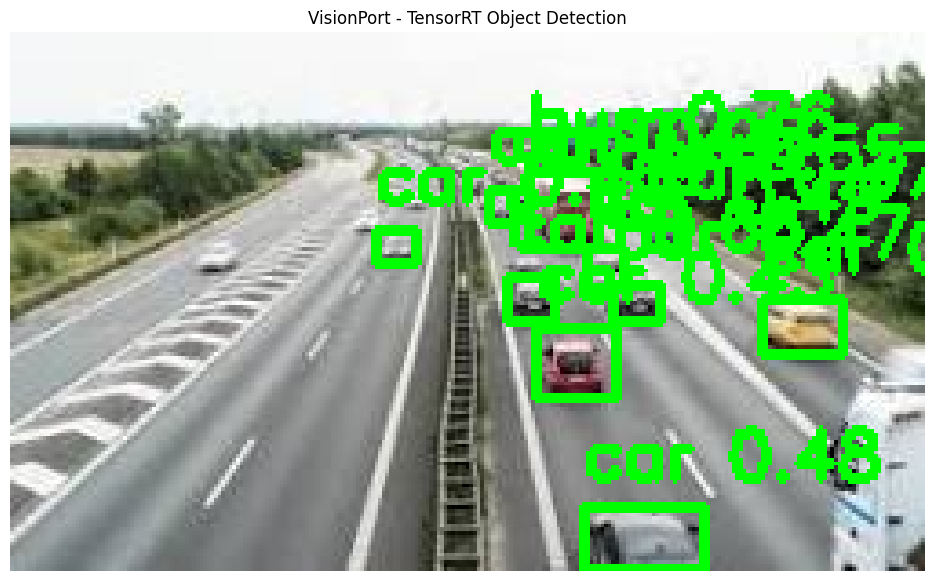

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Get TensorRT predictions
raw = output_tensor.detach().cpu().numpy()[0].T

# Extract bounding boxes and class scores
boxes = raw[:, :4]
class_scores = raw[:, 4:]

class_ids = np.argmax(class_scores, axis=1)
confidences = np.max(class_scores, axis=1)

# Confidence filtering
mask = confidences >= 0.25
boxes = boxes[mask]
confidences = confidences[mask]
class_ids = class_ids[mask]

# Convert xywh to xyxy
xyxy = np.zeros_like(boxes)
xyxy[:, 0] = boxes[:, 0] - boxes[:, 2] / 2
xyxy[:, 1] = boxes[:, 1] - boxes[:, 3] / 2
xyxy[:, 2] = boxes[:, 0] + boxes[:, 2] / 2
xyxy[:, 3] = boxes[:, 1] + boxes[:, 3] / 2

# NMS implementation
def calculate_iou(box, boxes):
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)

    area1 = (box[2]-box[0]) * (box[3]-box[1])
    area2 = (boxes[:, 2]-boxes[:, 0]) * (boxes[:, 3]-boxes[:, 1])

    return intersection / (area1 + area2 - intersection + 1e-7)

def classwise_nms(boxes, scores, classes, threshold=0.45):
    keep = []

    for cls in np.unique(classes):
        indices = np.where(classes == cls)[0]
        indices = indices[np.argsort(scores[indices])[::-1]]

        while len(indices):
            current = indices[0]
            keep.append(current)

            if len(indices) == 1:
                break

            ious = calculate_iou(boxes[current], boxes[indices[1:]])
            indices = indices[1:][ious < threshold]

    return keep

keep = classwise_nms(xyxy, confidences, class_ids)

# Map boxes back to original image coordinates
h, w = original_image.shape[:2]
gain = min(640 / h, 640 / w)
pad_x = (640 - round(w * gain)) / 2
pad_y = (640 - round(h * gain)) / 2

annotated = original_image.copy()

for idx in keep:
    x1, y1, x2, y2 = xyxy[idx]

    x1 = int(np.clip((x1 - pad_x) / gain, 0, w))
    y1 = int(np.clip((y1 - pad_y) / gain, 0, h))
    x2 = int(np.clip((x2 - pad_x) / gain, 0, w))
    y2 = int(np.clip((y2 - pad_y) / gain, 0, h))

    cls = int(class_ids[idx])
    conf = float(confidences[idx])

    label = f"{model.names[cls]} {conf:.2f}"

    cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(
        annotated, label, (x1, max(20, y1-8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
    )

print("TensorRT inference completed!")
print(f"GPU inference time: {inference_time:.2f} ms")
print(f"Detected objects: {len(keep)}")

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("VisionPort - TensorRT Object Detection")
plt.show()

In [ ]:
import torch
import numpy as np
import time

# Prepare PyTorch model on GPU
pytorch_model = model.model.cuda().eval()

# Use the same input for both models
x = input_tensor.contiguous()

# Warm-up
with torch.inference_mode():
    for _ in range(20):
        _ = pytorch_model(x)

for _ in range(20):
    context.execute_async_v3(stream.cuda_stream)

torch.cuda.synchronize()

# Benchmark settings
iterations = 100
pytorch_times = []
tensorrt_times = []

# PyTorch benchmark
with torch.inference_mode():
    for _ in range(iterations):
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)

        start.record()
        _ = pytorch_model(x)
        end.record()

        torch.cuda.synchronize()
        pytorch_times.append(start.elapsed_time(end))

# TensorRT benchmark
for _ in range(iterations):
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()
    context.execute_async_v3(stream.cuda_stream)
    end.record()

    torch.cuda.synchronize()
    tensorrt_times.append(start.elapsed_time(end))

# Results
pytorch_avg = np.mean(pytorch_times)
tensorrt_avg = np.mean(tensorrt_times)

print("PYTORCH vs TENSORRT BENCHMARK")
print("--------------------------------")
print(f"PyTorch average: {pytorch_avg:.3f} ms")
print(f"TensorRT average: {tensorrt_avg:.3f} ms")
print(f"PyTorch median: {np.median(pytorch_times):.3f} ms")
print(f"TensorRT median: {np.median(tensorrt_times):.3f} ms")
print(f"Speedup: {pytorch_avg / tensorrt_avg:.2f}x")

PYTORCH vs TENSORRT BENCHMARK
--------------------------------
PyTorch average: 7.831 ms
TensorRT average: 4.045 ms
PyTorch median: 7.525 ms
TensorRT median: 4.114 ms
Speedup: 1.94x


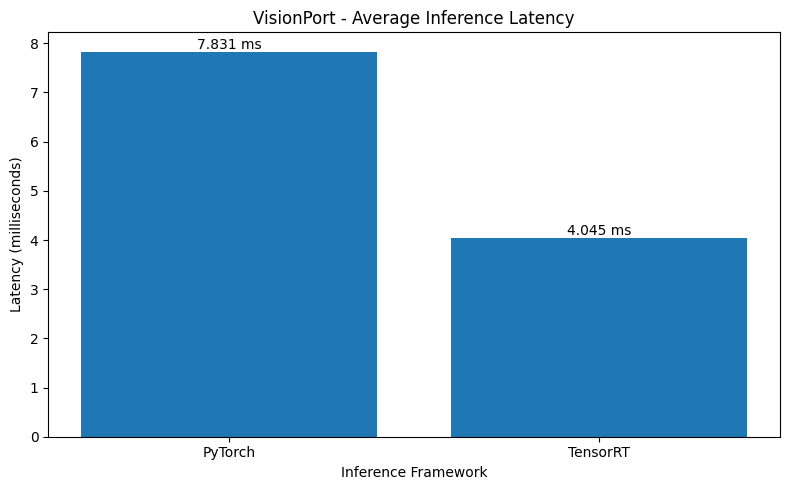

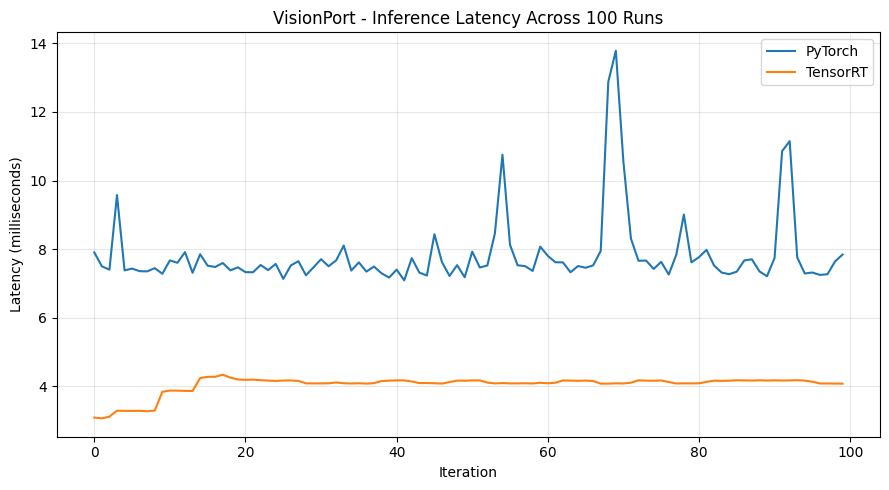

Both performance graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Graph 1: Average inference latency
models = ["PyTorch", "TensorRT"]
latencies = [pytorch_avg, tensorrt_avg]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, latencies)

plt.title("VisionPort - Average Inference Latency")
plt.ylabel("Latency (milliseconds)")
plt.xlabel("Inference Framework")

for bar, value in zip(bars, latencies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.3f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("latency_comparison.png", dpi=300)
plt.show()


# Graph 2: Inference latency distribution
plt.figure(figsize=(9, 5))

plt.plot(pytorch_times, label="PyTorch")
plt.plot(tensorrt_times, label="TensorRT")

plt.title("VisionPort - Inference Latency Across 100 Runs")
plt.xlabel("Iteration")
plt.ylabel("Latency (milliseconds)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("latency_distribution.png", dpi=300)
plt.show()

print("Both performance graphs saved successfully!")

In [ ]:
import os
import shutil

# Create Triton model repository
repo = "/content/model_repository/visionport_yolo/1"

os.makedirs(repo, exist_ok=True)

# Copy TensorRT engine into version 1
shutil.copy(
    "/content/yolov8n.engine",
    os.path.join(repo, "model.plan")
)

# Create Triton configuration
config = """
name: "visionport_yolo"
platform: "tensorrt_plan"
max_batch_size: 1

input [
  {
    name: "images"
    data_type: TYPE_FP32
    dims: [3, 640, 640]
  }
]

output [
  {
    name: "output0"
    data_type: TYPE_FP32
    dims: [84, 8400]
  }
]

instance_group [
  {
    count: 1
    kind: KIND_GPU
  }
]
"""

config_path = "/content/model_repository/visionport_yolo/config.pbtxt"

with open(config_path, "w") as f:
    f.write(config)

print("Triton model repository created!")

for root, dirs, files_list in os.walk("/content/model_repository"):
    print(root, files_list)

Triton model repository created!
/content/model_repository []
/content/model_repository/visionport_yolo ['config.pbtxt']
/content/model_repository/visionport_yolo/1 ['model.plan']


In [ ]:
import shutil
import subprocess

print("Docker executable:", shutil.which("docker"))

if shutil.which("docker"):
    subprocess.run(["docker", "version"])

print("\nTriton Server executable:", shutil.which("tritonserver"))

Docker executable: None

Triton Server executable: None


In [ ]:
%pip install -q nvidia-pytriton

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... canceled
ERROR: Operation cancelled by user


In [ ]:
import importlib.util

print("PyTriton installed:",
      importlib.util.find_spec("pytriton") is not None)

PyTriton installed: True


In [ ]:
import sys
import sysconfig
import subprocess
import glob
import os

print("Python:", sys.version)
print("Python library directory:", sysconfig.get_config_var("LIBDIR"))

print("\nGLIBC:")
subprocess.run(["ldd", "--version"])

libdir = sysconfig.get_config_var("LIBDIR")
print("\nMatching libpython files:")
print(glob.glob(os.path.join(libdir, "libpython*")))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python library directory: /usr/lib/x86_64-linux-gnu

GLIBC:

Matching libpython files:
['/usr/lib/x86_64-linux-gnu/libpython3.12.so.1.0', '/usr/lib/x86_64-linux-gnu/libpython3.13.so.1.0', '/usr/lib/x86_64-linux-gnu/libpython3.13.a', '/usr/lib/x86_64-linux-gnu/libpython3.12.a', '/usr/lib/x86_64-linux-gnu/libpython3.12.so.1', '/usr/lib/x86_64-linux-gnu/libpython3.13.so', '/usr/lib/x86_64-linux-gnu/libpython3.13.so.1', '/usr/lib/x86_64-linux-gnu/libpython3.12.so']


In [ ]:
import os
import subprocess
import time

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

os.makedirs("/content/empty_triton_repo", exist_ok=True)

with open("/tmp/triton_test.log", "w") as log:
    process = subprocess.Popen(
        [server, "--model-repository=/content/empty_triton_repo"],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(10)

print("Server process running:", process.poll() is None)
print("\nTriton log:")
with open("/tmp/triton_test.log") as f:
    print(f.read()[-4000:])

Server process running: True

Triton log:
                         |
+----------------------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| server_id                        | triton                                                                                                                                                                                                          |
| server_version                   | 2.45.0                                                                                                                                                                                                          |
| server_extensions                | classification sequence model_repository model_repository(unload_dependents) schedule_policy model_configuration system_shared_memory cuda_shared_memory 

In [ ]:
import os
import subprocess
import time

# Stop the test server
process.terminate()
process.wait(timeout=10)

# Start Triton with the actual model repository
server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

with open("/tmp/visionport_triton.log", "w") as log:
    triton_process = subprocess.Popen(
        [server, "--model-repository=/content/model_repository"],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(15)

print("Triton running:", triton_process.poll() is None)
print("\nTriton log:")
with open("/tmp/visionport_triton.log") as f:
    print(f.read()[-6000:])

Triton running: False

Triton log:
---+------+
| Repository Agent | Path |
+------------------+------+
+------------------+------+

I1112 05:30:37.835269 10518 server.cc:634] 
+---------+------+--------+
| Backend | Path | Config |
+---------+------+--------+
+---------+------+--------+

I1112 05:30:37.835294 10518 server.cc:677] 
+-----------------+---------+------------------------------------------------------------------------------------------------------------------------------------------+
| Model           | Version | Status                                                                                                                                   |
+-----------------+---------+------------------------------------------------------------------------------------------------------------------------------------------+
| visionport_yolo | 1       | UNAVAILABLE: Invalid argument: unable to find backend library for backend 'tensorrt', try specifying runtime on the model configur

In [ ]:
import os

base = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver"

print("Available Triton backends:")

backend_dir = os.path.join(base, "backends")

for item in os.listdir(backend_dir):
    print("-", item)

print("\nTriton Server version: 2.45.0")

Available Triton backends:
- python

Triton Server version: 2.45.0


In [ ]:
import tensorrt as trt
import torch

print("Triton Server: 2.45.0")
print("TensorRT:", trt.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("Compute capability:", torch.cuda.get_device_capability(0))

Triton Server: 2.45.0
TensorRT: 11.4.0.106
CUDA: 13.0
GPU: Tesla T4
Compute capability: (7, 5)


In [ ]:
import os

engine = "/content/yolov8n.engine"

print("TensorRT engine exists:", os.path.exists(engine))

if os.path.exists(engine):
    print("Engine size:", round(os.path.getsize(engine) / (1024 * 1024), 2), "MB")

TensorRT engine exists: True
Engine size: 163.86 MB


In [ ]:
import os
import subprocess

stub_dir = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/python_backend_stubs"

print("Available Python backend stubs:")
print(os.listdir(stub_dir))

print("\nPython 3.12:")
result = subprocess.run(
    ["/usr/bin/python3.12", "-c",
     "import sys; print(sys.version); import tensorrt; print(tensorrt.__version__)"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Available Python backend stubs:
['3.8', '3.12', '3.10', '3.11', '3.9']

Python 3.12:
3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]

Traceback (most recent call last):
  File "<string>", line 1, in <module>
ModuleNotFoundError: No module named 'tensorrt'



In [ ]:
import subprocess

result = subprocess.run(
    ["/usr/bin/python3.12", "-m", "pip", "--version"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)


/usr/bin/python3.12: No module named pip



In [ ]:
import sys
import tensorrt

print("Python executable:", sys.executable)
print("TensorRT version:", tensorrt.__version__)
print("TensorRT location:", tensorrt.__file__)

Python executable: /usr/bin/python3
TensorRT version: 11.4.0.106
TensorRT location: /usr/local/lib/python3.13/dist-packages/tensorrt/__init__.py


In [ ]:
import subprocess

subprocess.run([
    "bash", "-c",
    "ls -l /usr/bin/python3.12"
])

print("\nPython 3.12 package directories:")
subprocess.run([
    "bash", "-c",
    "find /usr/local/lib/python3.12 -maxdepth 3 -type d 2>/dev/null | head -20"
])


Python 3.12 package directories:


CompletedProcess(args=['bash', '-c', 'find /usr/local/lib/python3.12 -maxdepth 3 -type d 2>/dev/null | head -20'], returncode=0)

In [ ]:
import subprocess

stub = (
    "/usr/local/lib/python3.13/dist-packages/"
    "pytriton/tritonserver/python_backend_stubs/3.12/"
    "triton_python_backend_stub"
)

result = subprocess.run(
    ["ldd", stub],
    capture_output=True,
    text=True
)

print(result.stdout)

	linux-vdso.so.1 (0x00007ffef159c000)
	libcudart-8774224f.so.12.4.127 => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/python_backend_stubs/3.12/../../../../nvidia_pytriton.libs/libcudart-8774224f.so.12.4.127 (0x00007c0d0b600000)
	libpython3.12.so.1.0 => /lib/x86_64-linux-gnu/libpython3.12.so.1.0 (0x00007c0d0ad58000)
	libstdc++.so.6 => /lib/x86_64-linux-gnu/libstdc++.so.6 (0x00007c0d0aada000)
	libgcc_s.so.1 => /lib/x86_64-linux-gnu/libgcc_s.so.1 (0x00007c0d0b933000)
	libc.so.6 => /lib/x86_64-linux-gnu/libc.so.6 (0x00007c0d0a8c7000)
	/lib64/ld-linux-x86-64.so.2 (0x00007c0d0bac5000)
	libdl.so.2 => /lib/x86_64-linux-gnu/libdl.so.2 (0x00007c0d0b92c000)
	libpthread.so.0 => /lib/x86_64-linux-gnu/libpthread.so.0 (0x00007c0d0b927000)
	librt.so.1 => /lib/x86_64-linux-gnu/librt.so.1 (0x00007c0d0b922000)
	libm.so.6 => /lib/x86_64-linux-gnu/libm.so.6 (0x00007c0d0a7de000)
	libz.so.1 => /lib/x86_64-linux-gnu/libz.so.1 (0x00007c0d0b906000)
	libexpat.so.1 => /lib/x86_64-linux-gnu/libex

In [ ]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "--python", "/usr/bin/python3.12",
        "install", "--dry-run",
        "tensorrt-cu13==11.4.0.106"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-4000:])
print(result.stderr[-2000:])

Return code: 1

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 6

In [ ]:
import subprocess

result = subprocess.run(
    [
        "/usr/bin/python3.12",
        "-c",
        """
import sys
print("Python:", sys.version)

for package in ["numpy", "onnxruntime", "PIL"]:
    try:
        module = __import__(package)
        print(package, ":", getattr(module, "__version__", "available"))
    except ImportError:
        print(package, ": Not installed")
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
numpy : 1.26.4
onnxruntime : Not installed
PIL : Not installed




In [ ]:
import sys
import subprocess

packages_dir = "/content/triton_py312_packages"

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--only-binary=:all:",
        "--python-version", "3.12",
        "--implementation", "cp",
        "--abi", "cp312",
        "--platform", "manylinux_2_28_x86_64",
        "--platform", "manylinux2014_x86_64",
        "--target", packages_dir,
        "numpy==1.26.4",
        "onnxruntime",
        "pillow"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])
print(result.stderr[-2000:])

Return code: 0
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 40.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 47.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 76.9 MB/s  0:00:00
Using cached packaging-26.3-py3-none-any.whl (129 kB)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ml-dtypes 0.5.4 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
contourpy 1.4.0 req

In [ ]:
import subprocess
import os

env = os.environ.copy()
env["PYTHONPATH"] = "/content/triton_py312_packages"

code = """
import sys
import numpy
import onnxruntime
from PIL import Image

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("ONNX Runtime:", onnxruntime.__version__)
print("Pillow:", Image.__version__)

session = onnxruntime.InferenceSession(
    "/content/yolov8n.onnx",
    providers=["CPUExecutionProvider"]
)

print("ONNX model loaded successfully!")
print("Input:", session.get_inputs()[0].shape)
print("Output:", session.get_outputs()[0].shape)
"""

result = subprocess.run(
    ["/usr/bin/python3.12", "-c", code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Return code:", result.returncode)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
NumPy: 1.26.4
ONNX Runtime: 1.31.1
Pillow: 13.0.0
ONNX model loaded successfully!
Input: [1, 3, 640, 640]
Output: [1, 84, 8400]


Return code: 0


In [ ]:
import os
import shutil

repo = "/content/triton_python_model_repository/visionport_onnx/1"
os.makedirs(repo, exist_ok=True)

# Copy the existing ONNX model
shutil.copy(
    "/content/yolov8n.onnx",
    os.path.join(repo, "model.onnx")
)

# Triton model configuration
config = """
name: "visionport_onnx"
backend: "python"
max_batch_size: 1

input [
  {
    name: "images"
    data_type: TYPE_FP32
    dims: [3, 640, 640]
  }
]

output [
  {
    name: "output0"
    data_type: TYPE_FP32
    dims: [84, 8400]
  }
]

instance_group [
  {
    count: 1
    kind: KIND_CPU
  }
]
"""

config_path = "/content/triton_python_model_repository/visionport_onnx/config.pbtxt"

with open(config_path, "w") as f:
    f.write(config)

# Python backend implementation
model_code = '''
import os
import numpy as np
import onnxruntime as ort
import triton_python_backend_utils as pb_utils

class TritonPythonModel:

    def initialize(self, args):
        model_path = os.path.join(
            args["model_repository"],
            args["model_version"],
            "model.onnx"
        )

        self.session = ort.InferenceSession(
            model_path,
            providers=["CPUExecutionProvider"]
        )

    def execute(self, requests):
        responses = []

        for request in requests:
            input_tensor = pb_utils.get_input_tensor_by_name(
                request, "images"
            )

            images = input_tensor.as_numpy()

            result = self.session.run(
                ["output0"],
                {"images": images}
            )[0]

            output_tensor = pb_utils.Tensor(
                "output0",
                result.astype(np.float32)
            )

            responses.append(
                pb_utils.InferenceResponse(
                    output_tensors=[output_tensor]
                )
            )

        return responses

    def finalize(self):
        print("VisionPort ONNX model finalized.")
'''

model_path = os.path.join(repo, "model.py")

with open(model_path, "w") as f:
    f.write(model_code)

print("Triton Python model repository created!")

for root, dirs, files in os.walk("/content/triton_python_model_repository"):
    print(root, files)

Triton Python model repository created!
/content/triton_python_model_repository []
/content/triton_python_model_repository/visionport_onnx ['config.pbtxt']
/content/triton_python_model_repository/visionport_onnx/1 ['model.py', 'model.onnx']


In [ ]:
import os
import subprocess
import time

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

env = os.environ.copy()
env["PYTHONPATH"] = "/content/triton_py312_packages"

with open("/tmp/visionport_python_triton.log", "w") as log:
    visionport_process = subprocess.Popen(
        [
            server,
            "--model-repository=/content/triton_python_model_repository"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        env=env
    )

time.sleep(15)

print("Triton running:", visionport_process.poll() is None)

print("\nServer log:")
with open("/tmp/visionport_python_triton.log") as f:
    print(f.read()[-6000:])

Triton running: False

Server log:
-------------+------+
| Repository Agent | Path |
+------------------+------+
+------------------+------+

I1112 05:40:29.018451 13204 server.cc:634] 
+---------+------+--------+
| Backend | Path | Config |
+---------+------+--------+
+---------+------+--------+

I1112 05:40:29.018490 13204 server.cc:677] 
+-----------------+---------+----------------------------------------------------------------------------------------------------------------------------------------+
| Model           | Version | Status                                                                                                                                 |
+-----------------+---------+----------------------------------------------------------------------------------------------------------------------------------------+
| visionport_onnx | 1       | UNAVAILABLE: Invalid argument: unable to find backend library for backend 'python', try specifying runtime on the model config

In [ ]:
import os
import glob
import subprocess

base = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver"
backend_dir = os.path.join(base, "backends", "python")

print("Backend directory exists:", os.path.isdir(backend_dir))
print("\nBackend files:")
print(os.listdir(backend_dir) if os.path.isdir(backend_dir) else "Missing")

library = os.path.join(backend_dir, "libtriton_python.so")

if os.path.exists(library):
    print("\nLibrary dependencies:")
    result = subprocess.run(
        ["ldd", library],
        capture_output=True,
        text=True
    )
    print(result.stdout)
else:
    print("\nPython backend library is missing.")

print("\nAvailable backend libraries:")
print(glob.glob(base + "/backends/*/libtriton*.so"))

Backend directory exists: True

Backend files:
['__pycache__', 'triton_python_backend_utils.py', 'libtriton_python.so']

Library dependencies:
	linux-vdso.so.1 (0x00007ffc0a1f9000)
	libtritonserver-32e3abad.so => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python/../../../../nvidia_pytriton.libs/libtritonserver-32e3abad.so (0x0000798bb1ad5000)
	libarchive-6c65264d.so.13.6.0 => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python/../../../../nvidia_pytriton.libs/libarchive-6c65264d.so.13.6.0 (0x0000798bb19ff000)
	libcudart-8774224f.so.12.4.127 => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python/../../../../nvidia_pytriton.libs/libcudart-8774224f.so.12.4.127 (0x0000798bb1600000)
	libstdc++.so.6 => /lib/x86_64-linux-gnu/libstdc++.so.6 (0x0000798bb1382000)
	libgcc_s.so.1 => /lib/x86_64-linux-gnu/libgcc_s.so.1 (0x0000798bb19bf000)
	libc.so.6 => /lib/x86_64-linux-gnu/libc.so.6 (0x0000798bb116f000)
	/lib64/ld-lin

In [ ]:
import os
import subprocess
import time

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"
backend_dir = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends"

env = os.environ.copy()
env["PYTHONPATH"] = "/content/triton_py312_packages"

with open("/tmp/visionport_python_triton.log", "w") as log:
    visionport_process = subprocess.Popen(
        [
            server,
            "--model-repository=/content/triton_python_model_repository",
            f"--backend-directory={backend_dir}"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        env=env
    )

time.sleep(15)

print("Triton running:", visionport_process.poll() is None)

print("\nServer log:")
with open("/tmp/visionport_python_triton.log") as f:
    print(f.read()[-6000:])

Triton running: False

Server log:
-------------------------------------------------+
| Model           | Version | Status                                                                                                                                                                                                                                           |
+-----------------+---------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| visionport_onnx | 1       | UNAVAILABLE: Not found: triton_python_backend_stub is not found. Searched paths: /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python and /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python |
+-----------------+---------+------------------------------------------------------------------

In [ ]:
import os
import subprocess
import time

backend = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python"

stub_source = (
    "/usr/local/lib/python3.13/dist-packages/pytriton/"
    "tritonserver/python_backend_stubs/3.12/"
    "triton_python_backend_stub"
)

stub_target = os.path.join(backend, "triton_python_backend_stub")

print("Source exists:", os.path.isfile(stub_source))

if os.path.lexists(stub_target):
    os.remove(stub_target)

os.symlink(stub_source, stub_target)

print("Stub linked:", os.path.exists(stub_target))
print("Executable:", os.access(stub_target, os.X_OK))

Source exists: True
Stub linked: True
Executable: True


In [ ]:
import os
import subprocess
import time

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"
backend_dir = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends"

env = os.environ.copy()
env["PYTHONPATH"] = "/content/triton_py312_packages"

with open("/tmp/visionport_python_triton.log", "w") as log:
    visionport_process = subprocess.Popen(
        [
            server,
            "--model-repository=/content/triton_python_model_repository",
            f"--backend-directory={backend_dir}"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        env=env
    )

time.sleep(20)

print("Triton running:", visionport_process.poll() is None)

print("\nServer log:")
with open("/tmp/visionport_python_triton.log") as f:
    print(f.read()[-6000:])

Triton running: False

Server log:
-+
| visionport_onnx | 1       | UNAVAILABLE: Internal: ModuleNotFoundError: No module named 'onnxruntime'         |
|                 |         |                                                                                   |
|                 |         | At:                                                                               |
|                 |         |   /content/triton_python_model_repository/visionport_onnx/1/model.py(4): <module> |
|                 |         |   <frozen importlib._bootstrap>(488): _call_with_frames_removed                   |
|                 |         |   <frozen importlib._bootstrap_external>(995): exec_module                        |
|                 |         |   <frozen importlib._bootstrap>(950): _load_unlocked                              |
|                 |         |   <frozen importlib._bootstrap>(1334): _find_and_load_unlocked                    |
|                 |         |   <frozen importlib.

In [ ]:
model_path = "/content/triton_python_model_repository/visionport_onnx/1/model.py"

with open(model_path, "r") as f:
    code = f.read()

code = code.replace(
    "import os\nimport numpy as np",
    "import os\nimport sys\nsys.path.insert(0, '/content/triton_py312_packages')\nimport numpy as np"
)

with open(model_path, "w") as f:
    f.write(code)

print("Updated model.py")
print("\nFirst lines:")
print("\n".join(code.splitlines()[:8]))

Updated model.py

First lines:

import os
import sys
sys.path.insert(0, '/content/triton_py312_packages')
import numpy as np
import onnxruntime as ort
import triton_python_backend_utils as pb_utils



In [ ]:
import os
import subprocess
import time

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"
backend_dir = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends"

env = os.environ.copy()
env["PYTHONPATH"] = "/content/triton_py312_packages"

with open("/tmp/visionport_python_triton.log", "w") as log:
    visionport_process = subprocess.Popen(
        [
            server,
            "--model-repository=/content/triton_python_model_repository",
            f"--backend-directory={backend_dir}"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        env=env
    )

time.sleep(20)

print("Triton running:", visionport_process.poll() is None)

with open("/tmp/visionport_python_triton.log") as f:
    print(f.read()[-6000:])

Triton running: True
                                                                                                                                             |
+---------+---------------------------------------------------------------------------------------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| python  | /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends/python/libtriton_python.so | {"cmdline":{"auto-complete-config":"true","backend-directory":"/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/backends","min-compute-capability":"6.000000","default-max-batch-size":"4"}} |
+---------+---------------------------------------------------------------------------------------------------+---------------------------------------------------------------------------------------------

In [ ]:
import numpy as np
import cv2
import tritonclient.http as httpclient
from ultralytics.data.augment import LetterBox

# Connect to Triton
client = httpclient.InferenceServerClient(url="127.0.0.1:8000")

print("Server live:", client.is_server_live())
print("Server ready:", client.is_server_ready())
print("Model ready:", client.is_model_ready("visionport_onnx"))

# Load and preprocess image
img = cv2.imread("/content/traffic_image.jpg")
resized = LetterBox(new_shape=(640, 640))(image=img)
rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

input_data = np.transpose(rgb, (2, 0, 1))[None]
input_data = input_data.astype(np.float32) / 255.0

# Prepare Triton request
input_tensor = httpclient.InferInput(
    "images", input_data.shape, "FP32"
)
input_tensor.set_data_from_numpy(input_data)

output_tensor = httpclient.InferRequestedOutput("output0")

# Run inference
result = client.infer(
    "visionport_onnx",
    inputs=[input_tensor],
    outputs=[output_tensor]
)

predictions = result.as_numpy("output0")

print("\nTriton inference successful!")
print("Output shape:", predictions.shape)
print("Output data type:", predictions.dtype)

Server live: True
Server ready: True
Model ready: True

Triton inference successful!
Output shape: (1, 84, 8400)
Output data type: float32


In [ ]:
import importlib.util

for package in ["fastapi", "uvicorn", "tritonclient", "cv2"]:
    print(package, ":", importlib.util.find_spec(package) is not None)

fastapi : True
uvicorn : True
tritonclient : True
cv2 : True


In [ ]:
%%writefile /content/visionport_api.py

from fastapi import FastAPI, UploadFile, File, HTTPException
import numpy as np
import cv2
import tritonclient.http as httpclient
import time

app = FastAPI(
    title="VisionPort API Gateway",
    description="API Gateway for YOLOv8 inference using NVIDIA Triton",
    version="1.0"
)

TRITON_URL = "127.0.0.1:8000"
MODEL_NAME = "visionport_onnx"

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "service": "API Gateway",
        "status": "running"
    }

@app.get("/health")
def health():
    try:
        client = httpclient.InferenceServerClient(url=TRITON_URL)
        return {
            "api": "healthy",
            "triton_live": client.is_server_live(),
            "triton_ready": client.is_server_ready(),
            "model_ready": client.is_model_ready(MODEL_NAME)
        }
    except Exception as e:
        raise HTTPException(status_code=503, detail=str(e))

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    image_bytes = await file.read()
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)
    image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

    if image is None:
        raise HTTPException(status_code=400, detail="Invalid image")

    resized = cv2.resize(image, (640, 640))
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

    input_data = np.transpose(rgb, (2, 0, 1))[None]
    input_data = input_data.astype(np.float32) / 255.0

    client = httpclient.InferenceServerClient(url=TRITON_URL)

    inp = httpclient.InferInput("images", input_data.shape, "FP32")
    inp.set_data_from_numpy(input_data)

    out = httpclient.InferRequestedOutput("output0")

    start = time.time()
    result = client.infer(MODEL_NAME, [inp], outputs=[out])
    latency = (time.time() - start) * 1000

    predictions = result.as_numpy("output0")

    return {
        "status": "success",
        "model": MODEL_NAME,
        "output_shape": list(predictions.shape),
        "inference_latency_ms": round(latency, 2)
    }

Writing /content/visionport_api.py


In [ ]:
import subprocess
import time

with open("/tmp/visionport_api.log", "w") as log:
    api_process = subprocess.Popen(
        [
            "uvicorn",
            "visionport_api:app",
            "--app-dir", "/content",
            "--host", "0.0.0.0",
            "--port", "8080"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("API Gateway running:", api_process.poll() is None)

with open("/tmp/visionport_api.log") as f:
    print(f.read()[-3000:])

API Gateway running: False
INFO:     Started server process [15018]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8080): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.



In [ ]:
import subprocess
import time

with open("/tmp/visionport_api.log", "w") as log:
    api_process = subprocess.Popen(
        [
            "uvicorn",
            "visionport_api:app",
            "--app-dir", "/content",
            "--host", "0.0.0.0",
            "--port", "8081"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("API Gateway running:", api_process.poll() is None)

with open("/tmp/visionport_api.log") as f:
    print(f.read()[-3000:])

API Gateway running: True
INFO:     Started server process [15136]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8081 (Press CTRL+C to quit)



In [ ]:
import requests

# Test home endpoint
home = requests.get("http://127.0.0.1:8081/")
print("Home endpoint:", home.status_code)
print(home.json())

# Test health endpoint
health = requests.get("http://127.0.0.1:8081/health")
print("\nHealth endpoint:", health.status_code)
print(health.json())

Home endpoint: 200
{'project': 'VisionPort', 'service': 'API Gateway', 'status': 'running'}

Health endpoint: 200
{'api': 'healthy', 'triton_live': True, 'triton_ready': True, 'model_ready': True}


In [ ]:
import requests

image_path = "/content/traffic_image.jpg"

with open(image_path, "rb") as image:
    response = requests.post(
        "http://127.0.0.1:8081/predict",
        files={
            "file": ("traffic_image.jpg", image, "image/jpeg")
        }
    )

print("HTTP Status:", response.status_code)
print("API Response:")
print(response.json())

HTTP Status: 200
API Response:
{'status': 'success', 'model': 'visionport_onnx', 'output_shape': [1, 84, 8400], 'inference_latency_ms': 163.97}


In [ ]:
!ldd --version

ldd (Ubuntu GLIBC 2.39-0ubuntu8.9) 2.39
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.
Written by Roland McGrath and Ulrich Drepper.


In [ ]:
%pip install --only-binary=:all: nvidia-pytriton

INFO: pip is looking at multiple versions of nvidia-pytriton to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of nvidia-pytriton to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 29.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nvidia-pytriton]


In [ ]:
import pytriton
import os

print("PyTriton version:", getattr(pytriton, "__version__", "Installed"))

for root, dirs, files in os.walk(os.path.dirname(pytriton.__file__)):
    for file in files:
        if file == "tritonserver":
            print("Triton Server found:", os.path.join(root, file))

PyTriton version: 0.5.7
Triton Server found: /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver


In [ ]:
import subprocess

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

result = subprocess.run(
    [server, "--version"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 1

/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver: unrecognized option '--version'

Usage: tritonserver [options]
  --help
	Print usage

Server:
  --id <string>
	Identifier for this server.
  --exit-timeout-secs <integer>
	Timeout (in seconds) when exiting to wait for in-flight
	inferences to finish. After the timeout expires the server exits even if
	inferences are still in flight.

Logging:
  --log-verbose <integer>
	Set verbose logging level. Zero (0) disables verbose logging
	and values >= 1 enable verbose logging.
  --log-info <boolean>
	Enable/disable info-level logging.
  --log-warning <boolean>
	Enable/disable warning-level logging.
  --log-error <boolean>
	Enable/disable error-level logging.
  --log-format <string>
	Set the logging format. Options are "default" and "ISO8601".
	The default is "default". For "default", the log severity (L) and
	timestamp will be logged as "LMMDD hh:mm:ss.ssssss". For "ISO8601",
	the log format will be

In [ ]:
import os
import glob

base = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver"

print("TensorRT backend:")
print(glob.glob(base + "/backends/tensorrt/*"))

print("\nCUDA libraries:")
print(glob.glob(base + "/lib/lib*cuda*"))

TensorRT backend:
[]

CUDA libraries:
[]


In [ ]:
import os

base = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for f in files[:8]:
            print("  " * (level + 1) + f)

tritonserver/
  backends/
    python/
      triton_python_backend_utils.py
      libtriton_python.so
  bin/
    tritonserver
  caches/
    local/
      libtritoncache_local.so
  python_backend_stubs/
    3.8/
      triton_python_backend_stub
    3.12/
      triton_python_backend_stub
    3.10/
      triton_python_backend_stub
    3.11/
      triton_python_backend_stub
    3.9/
      triton_python_backend_stub


In [ ]:
import subprocess

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

subprocess.run(["ldd", server])

CompletedProcess(args=['ldd', '/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver'], returncode=0)

In [ ]:
import subprocess

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

result = subprocess.run(
    ["ldd", server],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("Errors:", result.stderr)

	linux-vdso.so.1 (0x0000786dd5c12000)
	libcudart-8774224f.so.12.4.127 => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/../../../nvidia_pytriton.libs/libcudart-8774224f.so.12.4.127 (0x0000786dd4800000)
	libb64-98cb6333.so.0d => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/../../../nvidia_pytriton.libs/libb64-98cb6333.so.0d (0x0000786dd4400000)
	libz.so.1 => /lib/x86_64-linux-gnu/libz.so.1 (0x0000786dd4b28000)
	libtritonserver-32e3abad.so => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/../../../nvidia_pytriton.libs/libtritonserver-32e3abad.so (0x0000786dd2f63000)
	libssl-091d763c.so.3 => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/../../../nvidia_pytriton.libs/libssl-091d763c.so.3 (0x0000786dd474f000)
	libcrypto-801de193.so.3 => /usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/../../../nvidia_pytriton.libs/libcrypto-801de193.so.3 (0x0000786dd2af9000)
	libstdc++.so.6 => /lib/x86_64-linux-g

In [ ]:
import os
import importlib.util

server = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver/bin/tritonserver"

print("Server executable exists:", os.path.exists(server))
print("PyTriton installed:", importlib.util.find_spec("pytriton") is not None)
print("TensorRT engine exists:", os.path.exists("/content/yolov8n.engine"))
print("Triton model repository exists:", os.path.exists("/content/model_repository"))

Server executable exists: True
PyTriton installed: True
TensorRT engine exists: True
Triton model repository exists: True


In [ ]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import importlib.util
import os

packages = ["ultralytics", "onnx", "tensorrt", "tritonclient", "pytriton"]

for package in packages:
    print(f"{package}:",
          "Installed" if importlib.util.find_spec(package) else "Missing")

print("\n/content files:")
print(os.listdir("/content"))

ultralytics: Installed
onnx: Installed
tensorrt: Installed
tritonclient: Installed
pytriton: Installed

/content files:
['.config', 'model_repository', 'yolov8n.engine', 'empty_triton_repo', 'yolov8n.pt', 'yolov8n.onnx', 'traffic_image.jpg', 'sample_data']


In [ ]:
import os

base = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver"

print("TensorRT backend exists:",
      os.path.exists(base + "/backends/tensorrt"))

TensorRT backend exists: False


In [ ]:
import os

base = "/usr/local/lib/python3.13/dist-packages/pytriton/tritonserver"

print("Python backend:",
      os.path.exists(base + "/backends/python/libtriton_python.so"))

stub_dir = base + "/python_backend_stubs"

print("\nAvailable Python backend stubs:")
print(os.listdir(stub_dir))

Python backend: True

Available Python backend stubs:
['3.8', '3.12', '3.10', '3.11', '3.9']


In [ ]:
import shutil
import subprocess

python312 = shutil.which("python3.12")
print("Python 3.12 executable:", python312)

if python312:
    subprocess.run([python312, "--version"])

Python 3.12 executable: /usr/bin/python3.12


In [ ]:
import subprocess

code = """
import sys
print("Python:", sys.version)

try:
    import tensorrt as trt
    print("TensorRT:", trt.__version__)
except Exception as e:
    print("TensorRT error:", e)

try:
    import numpy
    print("NumPy:", numpy.__version__)
except Exception as e:
    print("NumPy error:", e)
"""

subprocess.run(["/usr/bin/python3.12", "-c", code])

CompletedProcess(args=['/usr/bin/python3.12', '-c', '\nimport sys\nprint("Python:", sys.version)\n\ntry:\n    import tensorrt as trt\n    print("TensorRT:", trt.__version__)\nexcept Exception as e:\n    print("TensorRT error:", e)\n\ntry:\n    import numpy\n    print("NumPy:", numpy.__version__)\nexcept Exception as e:\n    print("NumPy error:", e)\n'], returncode=0)

In [ ]:
import subprocess

result = subprocess.run(
    ["/usr/bin/python3.12", "-c", """
import sys
print("Python:", sys.version)

try:
    import tensorrt as trt
    print("TensorRT:", trt.__version__)
except Exception as e:
    print("TensorRT error:", e)

try:
    import numpy
    print("NumPy:", numpy.__version__)
except Exception as e:
    print("NumPy error:", e)
"""],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
TensorRT error: No module named 'tensorrt'
NumPy: 1.26.4


